# BÀI THỰC HÀNH 1.3 : Phân tích dữ liệu Iris
**Họ và tên:** Thái Anh Lạc  
**MSSV:** 089206000860  
**Mã lớp học phần:** 012012204103  
**Môn học:** Khai thác dữ liệu (Data Mining)


In [1]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
iris = fetch_ucirepo(id=53) 
  
# data (as pandas dataframes) 
X = iris.data.features 
y = iris.data.targets 
  
# metadata 
print(iris.metadata) 
  
# variable information 
print(iris.variables) 


{'uci_id': 53, 'name': 'Iris', 'repository_url': 'https://archive.ics.uci.edu/dataset/53/iris', 'data_url': 'https://archive.ics.uci.edu/static/public/53/data.csv', 'abstract': 'A small classic dataset from Fisher, 1936. One of the earliest known datasets used for evaluating classification methods.\n', 'area': 'Biology', 'tasks': ['Classification'], 'characteristics': ['Tabular'], 'num_instances': 150, 'num_features': 4, 'feature_types': ['Real'], 'demographics': [], 'target_col': ['class'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 1936, 'last_updated': 'Tue Sep 12 2023', 'dataset_doi': '10.24432/C56C76', 'creators': ['R. A. Fisher'], 'intro_paper': {'ID': 191, 'type': 'NATIVE', 'title': 'The Iris data set: In search of the source of virginica', 'authors': 'A. Unwin, K. Kleinman', 'venue': 'Significance, 2021', 'year': 2021, 'journal': 'Significance, 2021', 'DOI': '1740-9713.01589', 'URL': 'https://www.semanticscholar.org

## 1. Đọc file CSV và hiển thị dữ liệu


In [9]:
import pandas as pd

# Ghép X và y thành 1 bảng hoàn chỉnh rồi lưu thành file iris.csv
df = pd.concat([X, y], axis=1)
df.to_csv("iris.csv", index=False)
df = pd.read_csv("iris.csv")

print("=== 5 DÒNG ĐẦU CỦA BẢNG DỮ LIỆU (HEAD) ===")
print(df.head())

print("\n=== 5 DÒNG CUỐI CỦA BẢNG DỮ LIỆU (TAIL) ===")
print(df.tail())

=== 5 DÒNG ĐẦU CỦA BẢNG DỮ LIỆU (HEAD) ===
   sepal length  sepal width  petal length  petal width        class
0           5.1          3.5           1.4          0.2  Iris-setosa
1           4.9          3.0           1.4          0.2  Iris-setosa
2           4.7          3.2           1.3          0.2  Iris-setosa
3           4.6          3.1           1.5          0.2  Iris-setosa
4           5.0          3.6           1.4          0.2  Iris-setosa

=== 5 DÒNG CUỐI CỦA BẢNG DỮ LIỆU (TAIL) ===
     sepal length  sepal width  petal length  petal width           class
145           6.7          3.0           5.2          2.3  Iris-virginica
146           6.3          2.5           5.0          1.9  Iris-virginica
147           6.5          3.0           5.2          2.0  Iris-virginica
148           6.2          3.4           5.4          2.3  Iris-virginica
149           5.9          3.0           5.1          1.8  Iris-virginica


## 2. Cho biết kiểu dữ liệu các cột


In [3]:
print("=== CÁC KIỂU DỮ LIỆU CỦA TỪNG CỘT (DF.DTYPES) ===")
print(df.dtypes)

print("\n=== THÔNG TIN TỔNG QUAN BẢNG DỮ LIỆU (DF.INFO()) ===")
df.info()


=== CÁC KIỂU DỮ LIỆU CỦA TỪNG CỘT (DF.DTYPES) ===
sepal length    float64
sepal width     float64
petal length    float64
petal width     float64
class               str
dtype: object

=== THÔNG TIN TỔNG QUAN BẢNG DỮ LIỆU (DF.INFO()) ===
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal length  150 non-null    float64
 1   sepal width   150 non-null    float64
 2   petal length  150 non-null    float64
 3   petal width   150 non-null    float64
 4   class         150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 7.9 KB


## 3. Hiển thị các giá trị thống kê (count, mean, std,...)


In [4]:
print("=== BẢNG THỐNG KÊ MÔ TẢ CHO CÁC THUỘC TÍNH SỐ (DF.DESCRIBE()) ===")
print(df.describe())

print("\n=== THỐNG KÊ TẦN SUẤT THUỘC TÍNH PHÂN LOẠI (CLASS) ===")
print(df['class'].value_counts())


=== BẢNG THỐNG KÊ MÔ TẢ CHO CÁC THUỘC TÍNH SỐ (DF.DESCRIBE()) ===
       sepal length  sepal width  petal length  petal width
count    150.000000   150.000000    150.000000   150.000000
mean       5.843333     3.054000      3.758667     1.198667
std        0.828066     0.433594      1.764420     0.763161
min        4.300000     2.000000      1.000000     0.100000
25%        5.100000     2.800000      1.600000     0.300000
50%        5.800000     3.000000      4.350000     1.300000
75%        6.400000     3.300000      5.100000     1.800000
max        7.900000     4.400000      6.900000     2.500000

=== THỐNG KÊ TẦN SUẤT THUỘC TÍNH PHÂN LOẠI (CLASS) ===
class
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


## 4. Trực quan hóa lần lượt các thuộc tính dùng các dạng đồ thị histogram


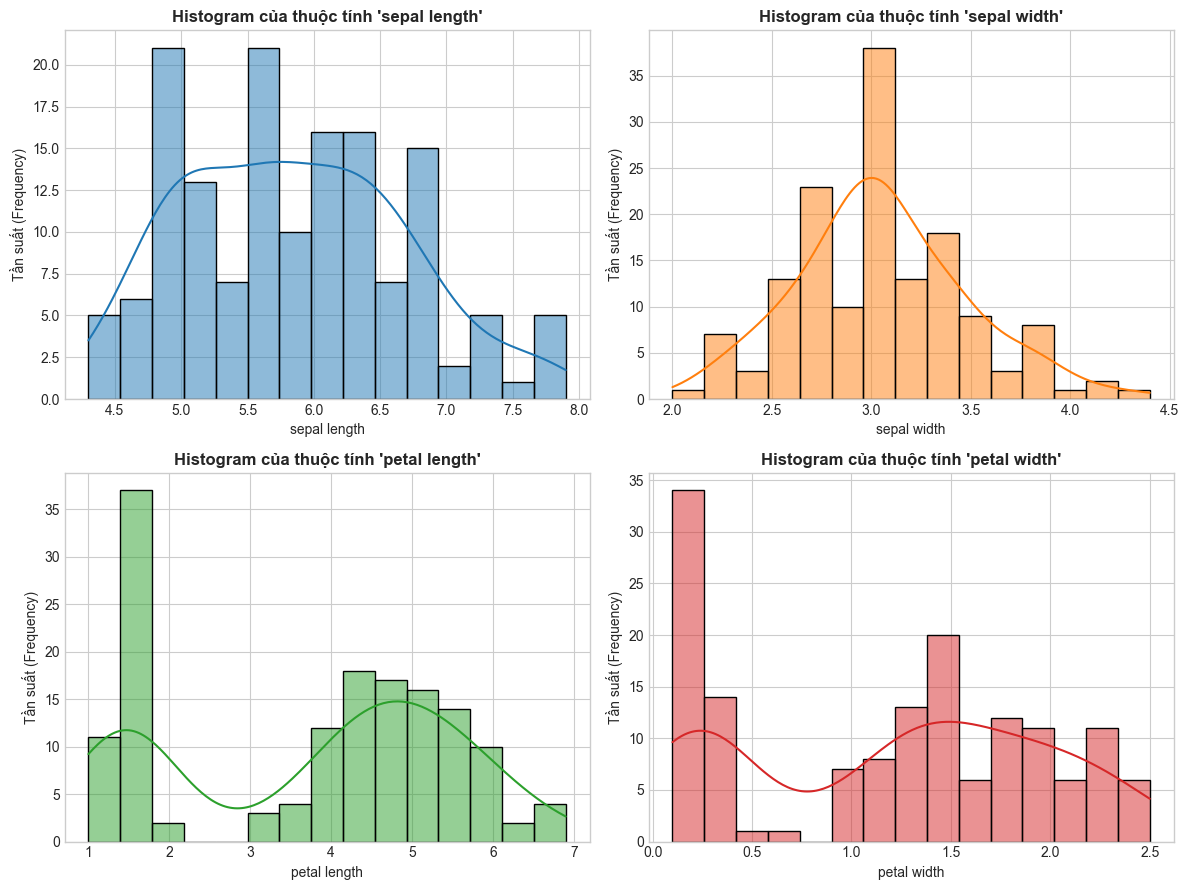

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Cấu hình giao diện biểu đồ
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# Danh sách các thuộc tính số
numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns

# Trực quan hóa Histogram cho từng thuộc tính số
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes = axes.flatten()

colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']

for i, col in enumerate(numeric_cols):
    sns.histplot(df[col], kde=True, ax=axes[i], color=colors[i], bins=15, edgecolor='black')
    axes[i].set_title(f"Histogram của thuộc tính '{col}'", fontweight='bold', fontsize=12)
    axes[i].set_xlabel(col, fontsize=10)
    axes[i].set_ylabel("Tần suất (Frequency)", fontsize=10)

plt.tight_layout()
plt.show()
